# Volatility-managed factors

Factor investing usually begins by asking which return sources to hold. Volatility management instead changes **how much exposure to take to the same factor over time**. Moreira and Muir (2017) propose reducing factor exposure after high realized variance and increasing it after calm months. In this notebook, I first explain that argument, then apply the rule to the Fama–French factors and momentum.

I focus on a one-month-lagged realized-variance rule. I then test whether constant unmanaged exposures explain the managed returns and look more closely at volatility-managed momentum. I use original French daily and monthly returns, keeping the stated timing and volatility-matching conventions.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().resolve()
ROOT = ROOT.parent if ROOT.name == "notebooks" else ROOT
sys.path.insert(0, str(ROOT / "src"))
from factor_asset_pricing.french_data import load_french, sample_coverage
RAW = ROOT / "data/raw/french"
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from factor_asset_pricing.asset_pricing_tests import factor_regressions, sharpe_ratio, spanning_regression
from factor_asset_pricing.volatility_management import aggregate_realized_variance, volatility_managed_return

plt.style.use("seaborn-v0_8-whitegrid")
pd.options.display.float_format = "{:,.3f}".format

# Preserve the previous notebook endpoint and the April 2015 normalization sample.
END = "2026-07"
NORMALIZATION_END = "2015-04"
rename3 = {"MKT": "mkt_rf", "SMB": "smb", "HML": "hml", "RF": "rf"}
rename5 = {"MKT": "ff5_mkt_rf", "SMB": "ff5_smb", "HML": "ff5_hml", "RMW": "rmw", "CMA": "cma", "RF": "ff5_rf"}
def public_factors(frequency):
    ff3 = load_french("ff3", RAW, frequency=frequency).rename(columns=rename3)
    ff5 = load_french("ff5", RAW, frequency=frequency).rename(columns=rename5)
    mom = load_french("momentum", RAW, frequency=frequency).rename(columns={"MOM": "mom"})
    return pd.concat([ff3, ff5, mom], axis=1).sort_index().loc[:END]

daily = public_factors("daily")
data = public_factors("monthly")
return_columns = ["mkt_rf", "smb", "hml", "rmw", "cma", "mom"]
rv = aggregate_realized_variance(daily.reset_index(), return_cols=return_columns,
                                 demean=True, min_obs=2).set_index("period")
rv.index = rv.index.to_timestamp()
# Reindex to the full monthly calendar before the library shifts variance by one row.
data = data.reindex(pd.date_range(data.index.min(), data.index.max(), freq="MS", name="date"))
data = data.join(rv)
for column in return_columns:
    measure = data[f"rv_{column}"]
    construction = volatility_managed_return(data[column], measure, normalize=False)
    calibration = volatility_managed_return(data[column].loc[:NORMALIZATION_END],
                                            measure.loc[:NORMALIZATION_END], normalize=True)
    valid = calibration["managed_return"].notna()
    constant = (calibration.loc[valid, "weight"] * calibration.loc[valid, "lagged_measure"]).iloc[0]
    data[f"rv_{column}_lag1"] = construction["lagged_measure"]
    data[f"weight_{column}"] = constant * construction["weight"]
    data[f"managed_{column}"] = constant * construction["managed_return"]
    assert np.isclose(calibration.loc[valid, "managed_return"].std(), calibration.loc[valid, "return"].std())
    assert data.loc[data[column].notna(), f"rv_{column}"].notna().all()
display(sample_coverage(data[[*return_columns, *[f"managed_{c}" for c in return_columns]]]))
print(f"Public monthly sample: {data.index.min():%B %Y}–{data.index.max():%B %Y}")


,start,end,observations,missing
mkt_rf,1926-07-01 00:00:00,2026-07-01 00:00:00,1201,0
smb,1926-07-01 00:00:00,2026-07-01 00:00:00,1201,0
hml,1926-07-01 00:00:00,2026-07-01 00:00:00,1201,0
rmw,1963-07-01 00:00:00,2026-07-01 00:00:00,757,444
cma,1963-07-01 00:00:00,2026-07-01 00:00:00,757,444
mom,1927-01-01 00:00:00,2026-07-01 00:00:00,1195,6
managed_mkt_rf,1926-08-01 00:00:00,2026-07-01 00:00:00,1200,1
managed_smb,1926-08-01 00:00:00,2026-07-01 00:00:00,1200,1
managed_hml,1926-08-01 00:00:00,2026-07-01 00:00:00,1200,1
managed_rmw,1963-08-01 00:00:00,2026-07-01 00:00:00,756,445


Public monthly sample: July 1926–July 2026


## 1. The economic intuition behind volatility management

The idea in Moreira and Muir (2017) is to take less exposure when recent risk is high and more when it is low. Large return movements tend to occur in clusters, so a volatile month gives some indication that the next month may also be volatile.

Taking the same position through both calm and turbulent periods can be unattractive if higher risk does not come with enough additional expected return. Volatility management uses that possibility to adjust the amount invested, rather than change which factor is held or predict whether its next return will be positive.

This only helps if recent volatility gives useful information about future risk and expected returns do not rise enough to offset the extra variance. It is not a guarantee that changing exposure improves every factor. I use the previous month's realized variance as a simple observable measure of risk, rather than try to estimate a more elaborate forecasting model.


### 1.1 Construction and information timing

The position rule has three steps: measure last month's risk, choose this month's exposure, then apply that exposure to the factor return.

First, calculate realized variance from the daily returns within each month:

$$
RV_t=\sum_{d\in t}\left(F_d-\bar F_t\right)^2.
$$

Here $F_d$ is the daily factor payoff and $\bar F_t$ is the average daily payoff in month $t$. Squaring and adding the deviations gives more weight to large movements. This calculation does not divide by the number of days or annualize the result. Daily and monthly returns must use the same units.

Next, use the completed previous month to choose the position for month $t$:

$$
w_t=\frac{c}{RV_{t-1}}.
$$

The position $w_t$ is larger after a low-variance month and smaller after a high-variance month. For a fixed positive $c$, doubling last month's variance halves the exposure. Only information observed before the holding month enters this part of the rule.

The managed factor payoff is then

$$
F_t^{VM}=w_tF_t.
$$

Here $F_t$ is the original monthly factor payoff. Because the weight is positive, the rule changes the amount of exposure without reversing the factor. Exposure above one requires leverage, while exposure below one scales the factor down. These are already excess-return payoffs, so the risk-free return is not subtracted again.

The constant $c$ sets the overall size of the position. To compare the strategies at the same volatility, I calculate it over a fixed sample $\mathcal A$:

$$
c=\frac{\operatorname{sd}_{\mathcal A}(F_t)}{\operatorname{sd}_{\mathcal A}(F_t/RV_{t-1})}.
$$

The numerator is the original factor's volatility. The denominator is the volatility of the scaled factor before applying $c$. Their ratio puts both on the same volatility scale. A positive constant rescales average return and volatility together, leaving the Sharpe ratio and intercept $t$-statistic unchanged.

For the regression series, this constant is estimated using observations through April 2015 and then held fixed. The cumulative comparison figures separately match volatility over their plotted samples. Within those estimation samples, the constants use information from later dates, so this scaling is a comparison convention rather than a fully real-time trading rule.

I assess whether changing exposure improves the Sharpe ratio and adds alpha beyond constant factor exposure. The rule can generate substantial leverage after calm months. The results exclude financing and transaction costs and do not impose leverage limits, so they show how the timing rule behaves rather than what an implemented investor would necessarily earn.


## 2. Example: Volatility-managing the Fama–French factors and momentum

For this example, I apply the rule to the market excess return, SMB, HML, RMW, CMA, and momentum. I use both daily and monthly returns from the [Kenneth French Data Library](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/data_library.html), because daily observations measure recent risk, while monthly observations give the factor payoff earned after choosing the exposure. MKT, SMB, and HML use FF3 sources, RMW and CMA use FF5 sources. FF5 benchmarks retain their separate SMB definition. The endpoint remains July 2026. Normalization ends April 2015. The strategy reacts to observed variance, without using a recession indicator.

### 2.1 Volatility clustering

I start with the monthly factor-return histories to see whether large return movements tend to cluster. If volatility were constant, large and small return fluctuations would be distributed relatively evenly through time. Instead, turbulent observations visibly occur in clusters, providing the empirical motivation for using recent realized volatility to adjust next month's exposure.

I calculate the risk measure from the original daily returns and check that each month's exposure follows the previous month's inverse variance. The French histories contain revisions, so they may differ from the data originally available at each date.


Construction check passed: all six public-data strategies match the library rule.


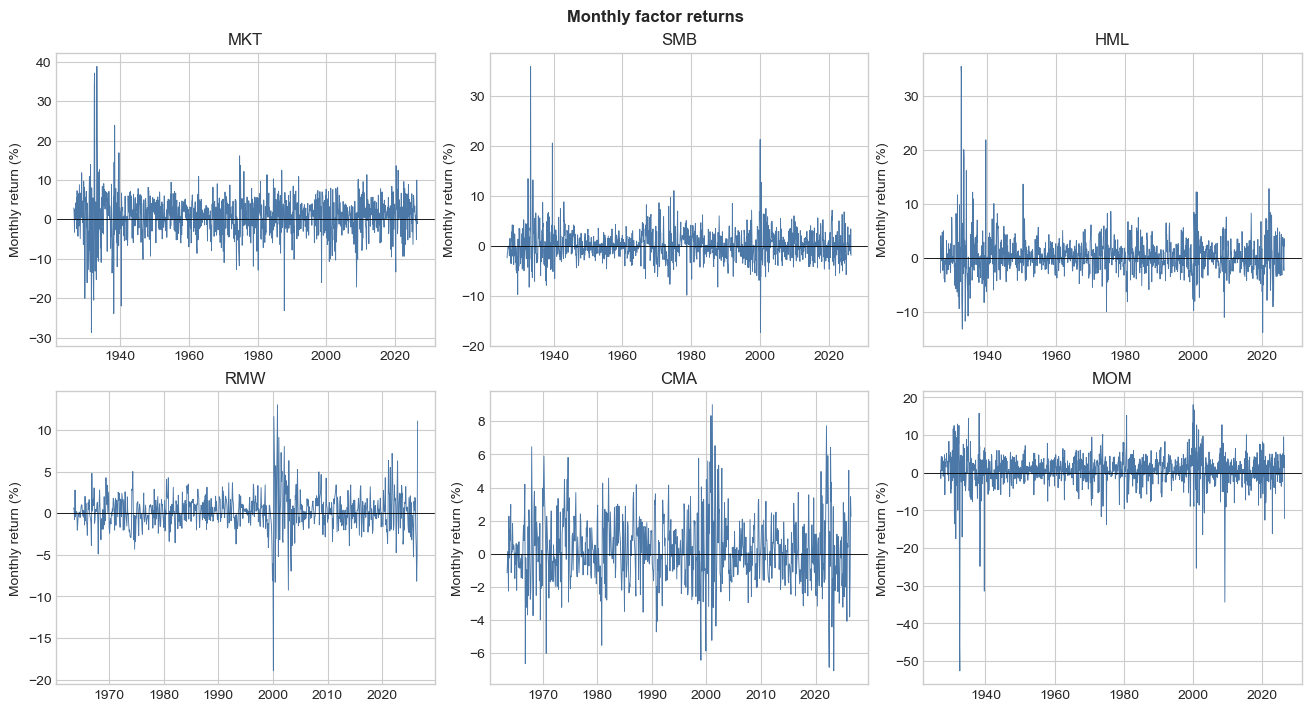

In [2]:
factor_columns = {
    "MKT": ("mkt_rf", "rv_mkt_rf_lag1", "managed_mkt_rf", "weight_mkt_rf"),
    "SMB": ("smb", "rv_smb_lag1", "managed_smb", "weight_smb"),
    "HML": ("hml", "rv_hml_lag1", "managed_hml", "weight_hml"),
    "RMW": ("rmw", "rv_rmw_lag1", "managed_rmw", "weight_rmw"),
    "CMA": ("cma", "rv_cma_lag1", "managed_cma", "weight_cma"),
    "MOM": ("mom", "rv_mom_lag1", "managed_mom", "weight_mom"),
}

integrity_rows = []
for name, (return_col, lagged_rv_col, managed_col, weight_col) in factor_columns.items():
    # The stored measure is already lagged, so lag=1 is reproduced by shifting it back once here.
    current_rv = data[lagged_rv_col].shift(-1)
    rebuilt = volatility_managed_return(
        data[return_col], current_rv, scaling="inverse_variance", lag=1, normalize=False
    )["managed_return"]
    valid = pd.concat([rebuilt, data[managed_col]], axis=1).dropna()
    ratio = (valid.iloc[:, 1] / valid.iloc[:, 0]).replace([np.inf, -np.inf], np.nan).dropna()
    integrity_rows.append({
        "Factor": name,
        "Minimum weight": data[weight_col].min(),
        "Correlation with library reconstruction": valid.corr().iloc[0, 1],
        "Variation in implied scale constant": ratio.std(),
    })

integrity = pd.DataFrame(integrity_rows).set_index("Factor")
assert integrity["Correlation with library reconstruction"].min() > 0.999999
assert integrity["Variation in implied scale constant"].max() < 1e-10
print("Construction check passed: all six public-data strategies match the library rule.")

fig, axes = plt.subplots(2, 3, figsize=(13, 7), sharex=False, constrained_layout=True)
for ax, (name, (return_col, _, _, _)) in zip(axes.flat, factor_columns.items()):
    series = 100 * data[return_col].dropna()
    ax.plot(series.index, series, color="#4C78A8", linewidth=0.65)
    ax.axhline(0, color="black", linewidth=0.6)
    ax.set(title=name, xlabel="", ylabel="Monthly return (%)")
fig.suptitle("Monthly factor returns", weight="bold")
plt.show()

The return histories display a familiar feature of financial data: large observations tend to arrive in clusters rather than being distributed evenly through time. The clustering is especially visible around major periods of market stress and is present in both the market and characteristic factors. This persistence is the empirical information exploited by the lagged-volatility rule. The strategy does not need to forecast the sign of next month's factor return.

The construction check confirms that the library applies the position rule above, including the chosen positive scaling constant. All weights are positive, so the strategy changes exposure without reversing the position.

### 2.2 The broad evidence across factors

I apply the spanning framework from [04](04_time_series_factor_regressions.ipynb), first using only the original factor as the benchmark:

$$
F_t^{VM}=\alpha+\beta F_t+\varepsilon_t,
\qquad H_0:\alpha=0.
$$

This tests whether changing exposure adds average return beyond a constant position in the same factor. Inference follows 04, with Newey–West standard errors and 12 monthly lags.

The first figure compares return paths at equal ex-post volatility. The second shows Sharpe ratios and own-factor alphas. Together they give the broad comparison before the closer examination of momentum.


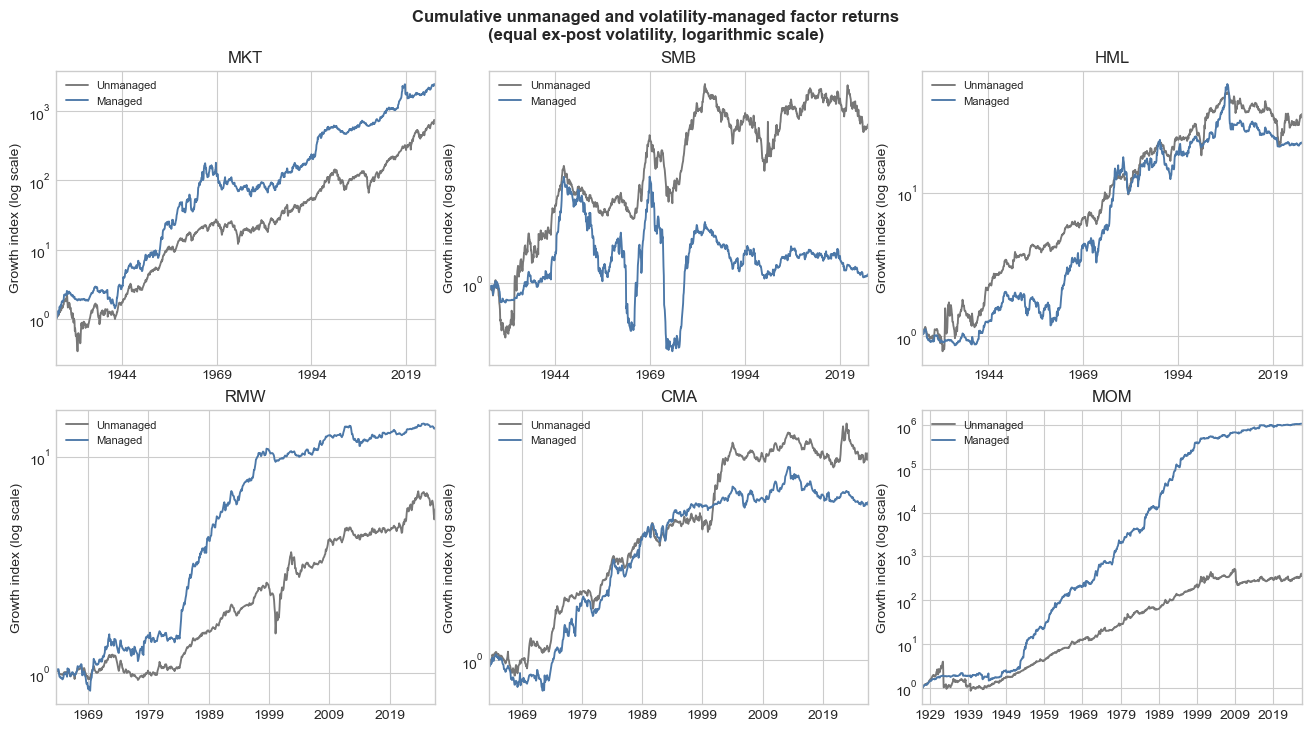

The cumulative panels compare each managed factor with its own unmanaged return at the same full-sample volatility. The evidence is visibly heterogeneous: RMW improves and momentum stands out, whereas the remaining managed paths do not consistently dominate. The logarithmic axes make proportional growth differences comparable across factors.

#### Risk-adjusted performance and own-factor spanning

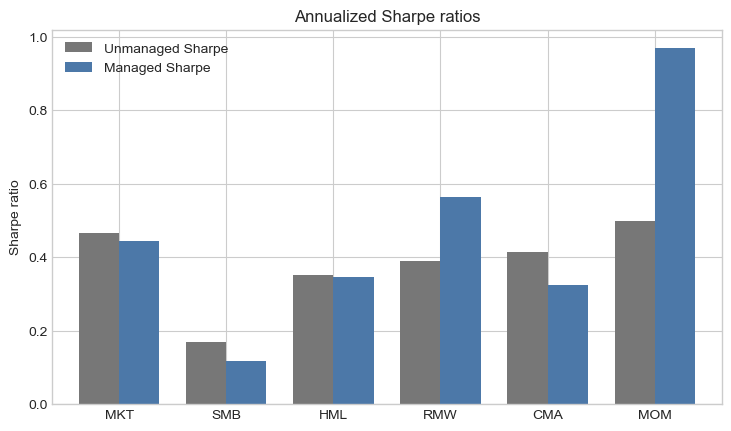

,Unmanaged SR,Managed SR,Alpha (% monthly),NW alpha t,Own-factor loading,NW loading t,Adjusted R²
Factor,,,,,,,
MKT,0.466,0.443,0.201,1.303,0.740,9.708,0.428
SMB,0.170,0.118,0.002,0.018,0.657,6.268,0.457
HML,0.350,0.346,0.138,1.148,0.759,6.703,0.378
RMW,0.389,0.562,0.204,2.924,0.505,4.184,0.314
CMA,0.415,0.325,0.028,0.650,0.596,7.433,0.436
MOM,0.498,0.970,0.950,5.463,0.567,5.612,0.266


In [3]:
original = pd.DataFrame({name: data[cols[0]] for name, cols in factor_columns.items()})
managed = pd.DataFrame({name: data[cols[2]] for name, cols in factor_columns.items()})
common = pd.concat(
    [original.add_suffix("_original"), managed.add_suffix("_managed")], axis=1
).dropna()

# Equalize volatility within each pair so the paths compare reward per unit of realized risk.
fig, axes = plt.subplots(2, 3, figsize=(13, 7.2), constrained_layout=True)
for ax, name in zip(axes.flat, factor_columns):
    pair = pd.concat([original[name], managed[name]], axis=1, keys=["Unmanaged", "Managed"]).dropna()
    pair["Managed"] *= pair["Unmanaged"].std() / pair["Managed"].std()
    wealth = (1 + pair).cumprod()
    wealth.plot(ax=ax, color=["#777777", "#4C78A8"], linewidth=1.35)
    ax.set_yscale("log")
    ax.set(title=name, xlabel="", ylabel="Growth index (log scale)")
    ax.legend(frameon=False, fontsize=8)
fig.suptitle("Cumulative unmanaged and volatility-managed factor returns\n(equal ex-post volatility, logarithmic scale)", weight="bold")
plt.show()

display(Markdown(
    "The cumulative panels compare each managed factor with its own unmanaged return at the same "
    "full-sample volatility. The evidence is visibly heterogeneous: RMW improves and momentum stands "
    "out, whereas the remaining managed paths do not consistently dominate. The logarithmic axes "
    "make proportional growth differences comparable across factors."
))

spanning_rows = []
for name in factor_columns:
    result = spanning_regression(
        common[f"{name}_managed"], common[[f"{name}_original"]], cov_type="HAC", hac_lags=12
    )
    spanning_rows.append({
        "Factor": name,
        "Unmanaged Sharpe": sharpe_ratio(common[f"{name}_original"]),
        "Managed Sharpe": sharpe_ratio(common[f"{name}_managed"]),
        "Alpha": 100 * result.params["const"],
        "Alpha SE": 100 * result.bse["const"],
        "Alpha t": result.tvalues["const"],
        "Own-factor loading": result.params.iloc[1],
        "Loading t": result.tvalues.iloc[1],
        "Adjusted R²": result.rsquared_adj,
    })
spanning_table = pd.DataFrame(spanning_rows).set_index("Factor")

display(Markdown("#### Risk-adjusted performance and own-factor spanning"))

fig, ax = plt.subplots(figsize=(7.2, 4.2), constrained_layout=True)
spanning_table[["Unmanaged Sharpe", "Managed Sharpe"]].plot.bar(
    ax=ax, color=["#777777", "#4C78A8"], width=0.75
)
ax.axhline(0, color="black", linewidth=0.7)
ax.set(title="Annualized Sharpe ratios", xlabel="", ylabel="Sharpe ratio")
ax.tick_params(axis="x", rotation=0)
ax.legend(frameon=False)
plt.show()

spanning_display = spanning_table[[
    "Unmanaged Sharpe", "Managed Sharpe", "Alpha", "Alpha t",
    "Own-factor loading", "Loading t", "Adjusted R²",
]].copy()
spanning_display.columns = [
    "Unmanaged SR", "Managed SR", "Alpha (% monthly)", "NW alpha t",
    "Own-factor loading", "NW loading t", "Adjusted R²",
]
display(spanning_display)

The six return panels immediately show that volatility management is not uniformly successful. The full-history MKT panel ends above its unmanaged counterpart, whereas SMB, HML, and CMA do not show sustained managed outperformance. RMW improves, while momentum is visually and statistically the clear outlier. The Sharpe table uses the shorter common six-factor sample (August 1963–July 2026), rather than each panel's full history. MKT's managed Sharpe is slightly lower on that common sample. The table confirms that only RMW and momentum have significantly positive own-factor alphas at the 5% level, and momentum's Sharpe ratio rises by far the most.

The own-factor loadings are positive and statistically significant for all six strategies. This is economically sensible: volatility management changes the amount invested in the original factor rather than replacing it with a different return source. The loading is not the average position weight. It summarizes how managed and original returns move together, which depends on both the changing weights and the returns. A loading below one therefore does not tell us how often the strategy reduces exposure. Adjusted $R^2$ shows that a constant exposure captures only part of the managed strategy's variation. The rule changes exposure using past risk. That does not guarantee a better result.

### 2.3 Asset Pricing Tests: CAPM, FF3, FF5, and FF5 + Momentum

A managed return can outperform its unmanaged counterpart and still be explained by familiar systematic exposures. I therefore test each managed factor against CAPM, the Fama–French three-factor model, the Fama–French five-factor model, and FF5 augmented with ordinary momentum. For managed momentum, adding ordinary momentum to the benchmark makes the comparison more demanding. It asks whether changing exposure adds average return even after we control directly for the unmanaged factor. For the vector of benchmark factor payoffs $\mathbf F_t$,

$$
F_t^{VM}=\alpha+\boldsymbol{\beta}'\mathbf F_t+\varepsilon_t,
\qquad H_0:\alpha=0.
$$

The coefficients have the same interpretation as in 04. Here the comparison isolates whether timing adds average return beyond the broader benchmark, rather than just the original factor.

Here FF3 and FF5 use their separate published FF3 and FF5 benchmark columns. This differs from the nested FF5-SMB convention in Notebooks 03 and 04. I keep those separate published definitions in this comparison. The six own-factor regressions use the same months. The multifactor regressions instead use all complete observations for each return and benchmark, so their dates can differ. The momentum/downside comparison has its own fixed sample too. I therefore interpret differences in alpha with both the benchmark and sample period in mind.


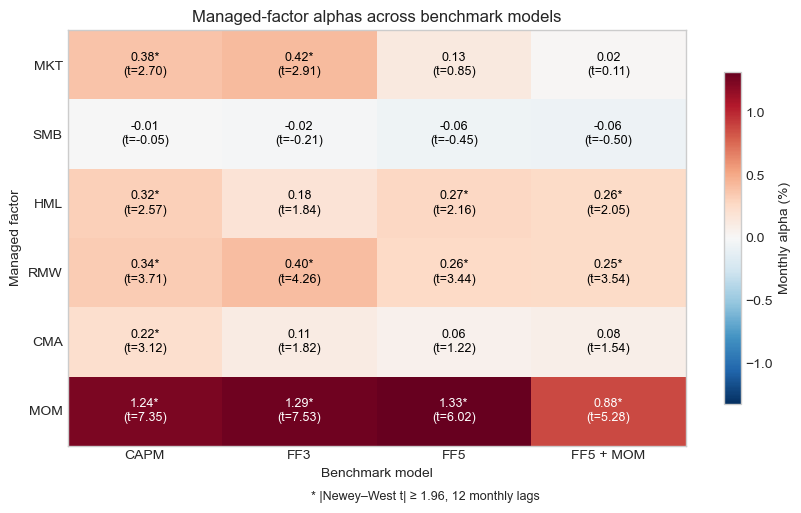

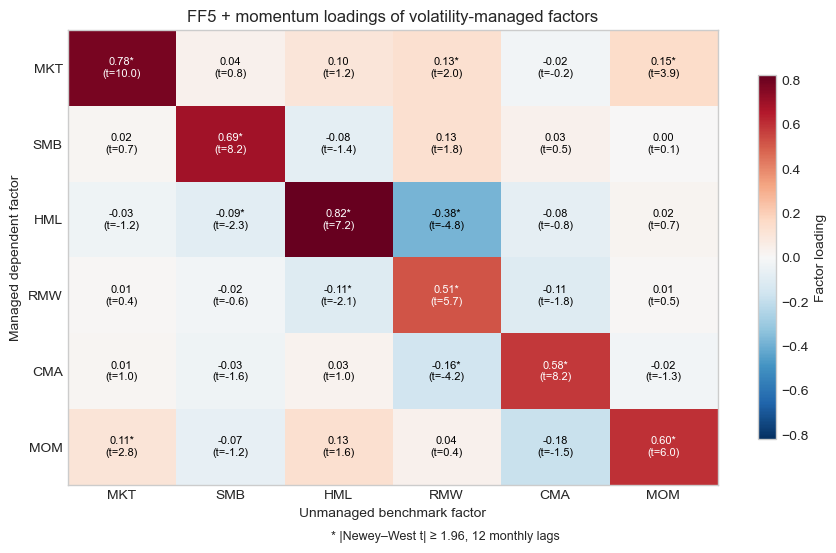

In [4]:
models = {
    "CAPM": ["mkt_rf"],
    "FF3": ["mkt_rf", "smb", "hml"],
    "FF5": ["ff5_mkt_rf", "ff5_smb", "ff5_hml", "rmw", "cma"],
    "FF5 + MOM": ["ff5_mkt_rf", "ff5_smb", "ff5_hml", "rmw", "cma", "mom"],
}

model_rows = []
model_fits = {}
for model_name, regressors in models.items():
    for factor_name, (_, _, managed_col, _) in factor_columns.items():
        sample = data[[managed_col, *regressors]].dropna()
        result = spanning_regression(
            sample[managed_col], sample[regressors], cov_type="HAC", hac_lags=12
        )
        model_fits[(factor_name, model_name)] = result
        model_rows.append({
            "Model": model_name,
            "Managed factor": factor_name,
            "Alpha (% monthly)": 100 * result.params["const"],
            "HAC t(alpha)": result.tvalues["const"],
            "Adjusted R²": result.rsquared_adj,
        })

model_table = pd.DataFrame(model_rows)
alpha_grid = model_table.pivot(index="Managed factor", columns="Model", values="Alpha (% monthly)")
t_grid = model_table.pivot(index="Managed factor", columns="Model", values="HAC t(alpha)")
alpha_grid = alpha_grid.loc[list(factor_columns), list(models)]
t_grid = t_grid.loc[list(factor_columns), list(models)]

fig, ax = plt.subplots(figsize=(8.6, 5.0))
limit = np.abs(alpha_grid.to_numpy()).max()
image = ax.imshow(alpha_grid, cmap="RdBu_r", aspect="auto", vmin=-limit, vmax=limit)
for row in range(alpha_grid.shape[0]):
    for col in range(alpha_grid.shape[1]):
        stars = "*" if abs(t_grid.iloc[row, col]) >= 1.96 else ""
        ax.text(col, row, f"{alpha_grid.iloc[row, col]:.2f}{stars}\n(t={t_grid.iloc[row, col]:.2f})",
                ha="center", va="center", fontsize=9,
                color="white" if abs(alpha_grid.iloc[row, col]) > 0.6 * limit else "black")
ax.set(
    title="Managed-factor alphas across benchmark models",
    xlabel="Benchmark model", ylabel="Managed factor",
    xticks=range(len(alpha_grid.columns)), xticklabels=alpha_grid.columns,
    yticks=range(len(alpha_grid.index)), yticklabels=alpha_grid.index,
)
ax.grid(False)
fig.colorbar(image, ax=ax, label="Monthly alpha (%)", shrink=0.8)
fig.text(0.5, -0.01, "* |Newey–West t| ≥ 1.96, 12 monthly lags", ha="center", fontsize=9)
plt.tight_layout()
plt.show()

richest_model = "FF5 + MOM"
regressor_labels = {
    "ff5_mkt_rf": "MKT", "ff5_smb": "SMB", "ff5_hml": "HML",
    "rmw": "RMW", "cma": "CMA", "mom": "MOM",
}
loading_grid = pd.DataFrame(index=factor_columns, columns=regressor_labels.values(), dtype=float)
loading_t_grid = loading_grid.copy()
for factor_name in factor_columns:
    fit = model_fits[(factor_name, richest_model)]
    for regressor, label in regressor_labels.items():
        loading_grid.loc[factor_name, label] = fit.params[regressor]
        loading_t_grid.loc[factor_name, label] = fit.tvalues[regressor]

fig, ax = plt.subplots(figsize=(9, 5.4))
loading_limit = np.abs(loading_grid.to_numpy()).max()
image = ax.imshow(loading_grid, cmap="RdBu_r", aspect="auto",
                  vmin=-loading_limit, vmax=loading_limit)
for row in range(loading_grid.shape[0]):
    for col in range(loading_grid.shape[1]):
        stars = "*" if abs(loading_t_grid.iloc[row, col]) >= 1.96 else ""
        ax.text(col, row, f"{loading_grid.iloc[row, col]:.2f}{stars}\n(t={loading_t_grid.iloc[row, col]:.1f})",
                ha="center", va="center", fontsize=8,
                color="white" if abs(loading_grid.iloc[row, col]) > 0.6 * loading_limit else "black")
ax.set(
    title="FF5 + momentum loadings of volatility-managed factors",
    xlabel="Unmanaged benchmark factor", ylabel="Managed dependent factor",
    xticks=range(len(loading_grid.columns)), xticklabels=loading_grid.columns,
    yticks=range(len(loading_grid.index)), yticklabels=loading_grid.index,
)
ax.grid(False)
fig.colorbar(image, ax=ax, label="Factor loading", shrink=0.8)
fig.text(0.5, -0.01, "* |Newey–West t| ≥ 1.96, 12 monthly lags", ha="center", fontsize=9)
plt.tight_layout()
plt.show()

Volatility-managed momentum remains the strongest result under the CAPM, FF3, and FF5. Adding ordinary momentum is the more stringent test: its monthly alpha falls to about 0.88%, but remains highly significant with a Newey–West $t$-statistic of 5.28. At the same time, volatility-managed momentum has a MOM loading of about 0.60 ($t=6.00$). It is therefore clearly related to ordinary momentum, as a timed version should be, but a constant combination of FF5 and MOM still does not reproduce its average return.

The broader loading heatmap reinforces this interpretation. The large, significant diagonal loadings show that most managed factors retain substantial exposure to their underlying unmanaged factors. Volatility management changes exposure through time rather than creating unrelated return sources. The off-diagonal estimates reveal overlap with other benchmarks, while the alpha heatmap shows whether those combined constant exposures span the managed return.

### 2.4 Downside-risk management

Sharpe ratios summarize average return per unit of total volatility, but momentum is particularly exposed to abrupt reversals. To examine that risk, I also report the empirical 5% loss quantile, expected shortfall conditional on being in that tail, maximum drawdown, skewness, and excess kurtosis. These measures show the losses and return shape observed in this sample. They do not guarantee what the next loss will look like.

The crash-risk motivation follows Daniel and Moskowitz (2016). For the empirical return quantile $q_{0.05}$, the displayed loss measures are $VaR_{0.05}=-q_{0.05}$ and $ES_{0.05}=-\operatorname{mean}\{F_t:F_t\le q_{0.05}\}$. They are reported as loss magnitudes: larger positive values indicate worse losses. Drawdowns retain their negative return convention. Drawdown includes initial wealth:

$$W_0=1,\qquad W_t=\prod_{s=1}^t(1+F_s),\qquad D_t=\frac{W_t}{\max_{0\le s\le t}W_s}-1.$$

Maximum drawdown is $\min_t D_t$. Including $W_0$ ensures a first-month loss is counted. These are factor comparison indices under the convention explained in 03, rather than complete accounts including short financing and collateral.


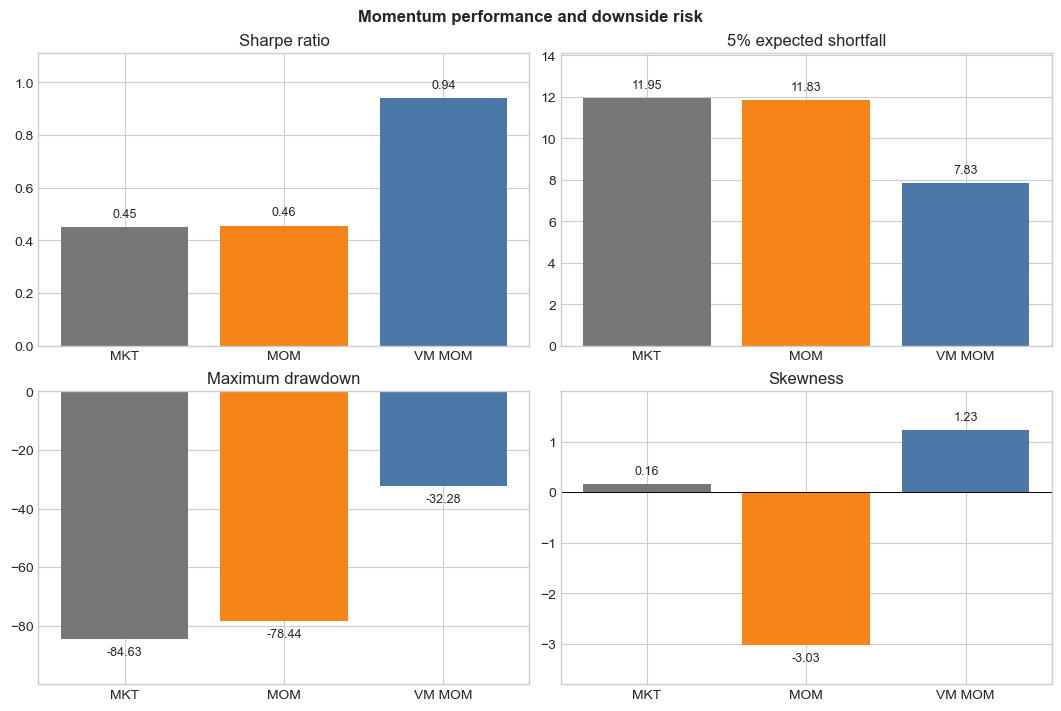

In [5]:
def downside_statistics(series):
    returns = series.dropna()
    wealth = (1 + returns).cumprod()
    drawdown = wealth / wealth.cummax().clip(lower=1) - 1
    cutoff = returns.quantile(0.05)
    return {
        "Annualized Sharpe": sharpe_ratio(returns),
        "5% loss quantile (%)": -100 * cutoff,
        "Expected shortfall (%)": -100 * returns[returns <= cutoff].mean(),
        "Maximum drawdown (%)": 100 * drawdown.min(),
        "Skewness": returns.skew(),
        "Excess kurtosis": returns.kurt(),
    }

momentum_sample = data[["mkt_rf", "mom", "managed_mom"]].dropna()
risk_table = pd.DataFrame({
    "Market": downside_statistics(momentum_sample["mkt_rf"]),
    "Momentum": downside_statistics(momentum_sample["mom"]),
    "Volatility-managed momentum": downside_statistics(momentum_sample["managed_mom"]),
}).T

metrics = ["Annualized Sharpe", "Expected shortfall (%)", "Maximum drawdown (%)", "Skewness"]
titles = ["Sharpe ratio", "5% expected shortfall", "Maximum drawdown", "Skewness"]
colors = ["#777777", "#F58518", "#4C78A8"]
fig, axes = plt.subplots(2, 2, figsize=(10.5, 7), constrained_layout=True)
for ax, metric, title in zip(axes.flat, metrics, titles):
    values = risk_table[metric]
    ax.bar(range(len(values)), values, color=colors)
    ax.margins(y=0.18)
    ax.axhline(0, color="black", linewidth=0.7)
    ax.set(title=title, xticks=range(len(values)), xticklabels=["MKT", "MOM", "VM MOM"])
    for position, value in enumerate(values):
        ax.annotate(f"{value:.2f}", xy=(position, value),
                    xytext=(0, 5 if value >= 0 else -5),
                    textcoords="offset points", ha="center",
                    va="bottom" if value >= 0 else "top", fontsize=9)
fig.suptitle("Momentum performance and downside risk", weight="bold")
plt.show()

Ordinary momentum has a deep maximum drawdown and strongly negative skewness, consistent with its well-known crash exposure. Volatility-managed momentum has a markedly higher Sharpe ratio, a substantially smaller drawdown, less severe expected shortfall, and positive sample skewness. The inverse-variance rule increases exposure after calm months and reduces exposure after turbulent months. These statistics describe the losses observed in the sample, without showing exactly which risk conditions produced the average gain. The strategy responds to past volatility, rather than predicting the next crash or recession.

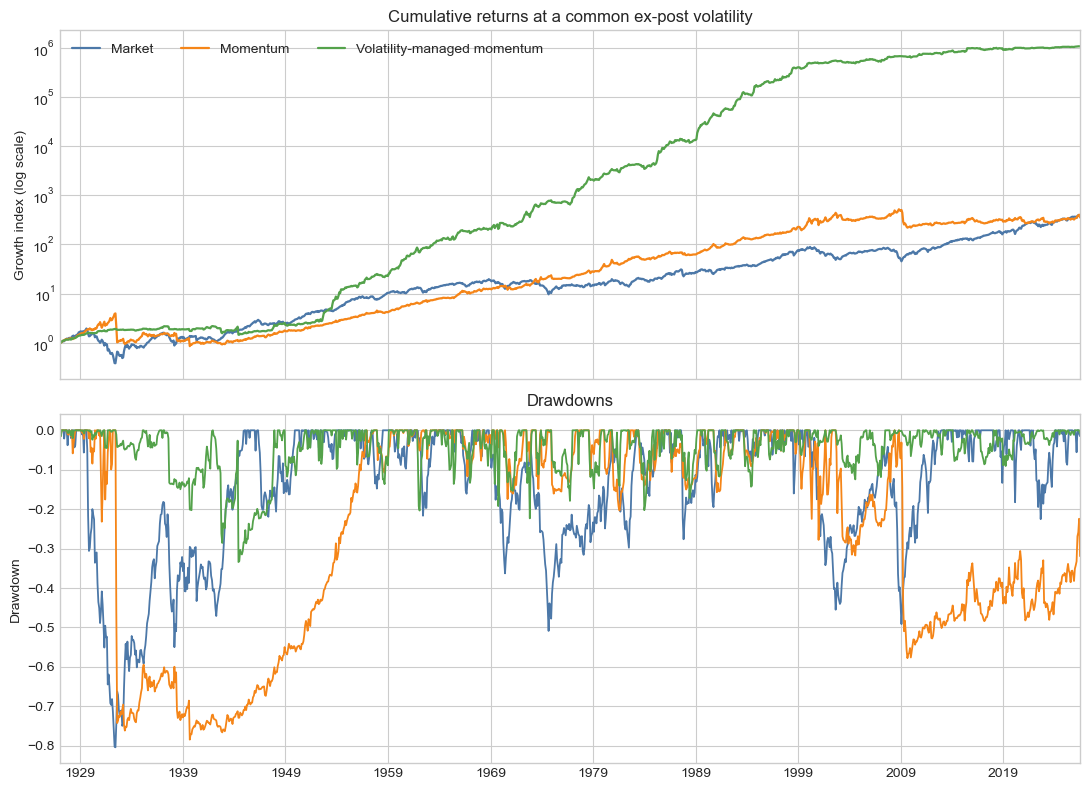

In [6]:
# Put the three series on momentum's full-sample volatility for a visual risk comparison.
target_volatility = momentum_sample["mom"].std()
scaled = momentum_sample.mul(target_volatility / momentum_sample.std())
scaled.columns = ["Market", "Momentum", "Volatility-managed momentum"]

wealth = (1 + scaled).cumprod()
drawdowns = wealth.div(wealth.cummax().clip(lower=1)).sub(1)

fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True)
colors = ["#4C78A8", "#F58518", "#54A24B"]
wealth.plot(ax=axes[0], color=colors, linewidth=1.6)
axes[0].set_yscale("log")
axes[0].set_title("Cumulative returns at a common ex-post volatility")
axes[0].set_ylabel("Growth index (log scale)")
axes[0].legend(frameon=False, ncol=3)

drawdowns.plot(ax=axes[1], color=colors, linewidth=1.3)
axes[1].set_title("Drawdowns")
axes[1].set_ylabel("Drawdown")
axes[1].set_xlabel("")
axes[1].legend().remove()
plt.tight_layout()
plt.show()

At the same ex-post volatility, managed momentum compounds more strongly and avoids much of ordinary momentum's prolonged crash drawdowns. The logarithmic scale keeps the market and unmanaged momentum paths visible despite the large difference in terminal values. The cumulative series is a normalized growth index for comparing return paths. The factor-wealth distinction from 03 and 06 still applies. The index compares payoffs rather than a complete investor account, and the timed strategy may use leverage.

**Limitations.** The central result is specific rather than universal. Lagged inverse-variance scaling adds strong time-series alpha and improves downside outcomes for momentum, with smaller or less robust gains for most Fama–French factors. The evidence is in-sample and gross of implementation frictions. The weights are uncapped, and the volatility-matching constant uses full-sample information. A deployable strategy would require real-time normalization, leverage limits, financing and trading costs, and out-of-sample evaluation. Testing a strategy an investor could actually follow would also require historical data vintages and explicit implementation costs.

## References

- Daniel, K., and Moskowitz, T. J. (2016). Momentum crashes. *Journal of Financial Economics*, 122(2), 221–247. [DOI](https://doi.org/10.1016/j.jfineco.2015.12.002).
- Moreira, A., and Muir, T. (2017). Volatility-managed portfolios. *The Journal of Finance*, 72(4), 1611–1644. [DOI](https://doi.org/10.1111/jofi.12513).
- Kenneth R. French Data Library. [Factor and portfolio data](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/data_library.html).
